In [75]:
import numpy as np
import matplotlib.pyplot as plt

In [181]:
class Memristor():
    def __init__(self, x_start=0.5, R_on=19.4, R_off=101.1):
        """
        модель Вудса-Уиллиса
        - x: текущее состояние (0..1)
        - R_on, R_off: минимальное и максимальное сопротивление (Ом)
        - k: коэффициент скорости изменения состояния
        """
        self.x = x_start
        self.R_on = R_on
        self.R_off = R_off
        self.p = 1

    def get_R(self):
        return self.R_off + (self.R_on - self.R_off) * self.x

    def get_x(self):
        return self.x * 1.

    def upd_x(self, dq):
        if dq > 0:
            self.x = 1
        else:
            self.x -= dq * self.f_off(self.x)
            
        self.x = max(min(0.95, self.x), 0.05)

    def calc_R(self, x):
        return self.R_off + (self.R_on - self.R_off) * x
    
    def f_off(self, x):
        f = 2.7e1 * (x - 0.49)**2 - 4.3e0
        return min(f, -1e-1)

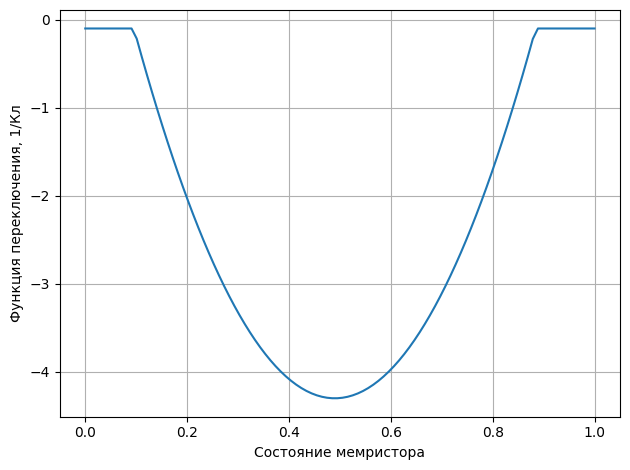

In [147]:
mem = Memristor()
x_arr = np.linspace(0, 1, 100)
plt.plot(x_arr, [mem.f_off(x) for x in x_arr])
plt.xlabel('Состояние мемристора')
plt.ylabel('Функция переключения, 1/Кл')
plt.grid(True)
plt.tight_layout()
plt.show()

# Схема с эксперимента. 
# Последовательное соединение источника тока, мемристора и резистора 220 Ом.

In [189]:
# ----------------------------
# Параметры схемы и моделирования
# ----------------------------
T = 1e2                # время моделирования, с
dt = 1e-1                # шаг по времени, с
N = int(T/dt)

# Характеристики элементов
mem = Memristor(x_start=0.95) # мемристор
Rl = 220 # сопротивление последовательное

# Источник напряжения
t = np.linspace(0, T, N)

V_in = np.concatenate([np.full(N//10, 5), np.full(8 * N//10, -5), np.full(N//10, 5)])


# Массивы для результатов
x_mem = np.zeros(N)
V_mem = np.zeros(N)
I_mem = np.zeros(N)

In [191]:
for i in range(N):
    Rm = mem.get_R()
    I_mem[i] = V_in[i] / (Rm + Rl)
    V_mem[i] = I_mem[i] * Rm
    
    mem.upd_x(I_mem[i] * dt)
    x_mem[i] = mem.get_x()

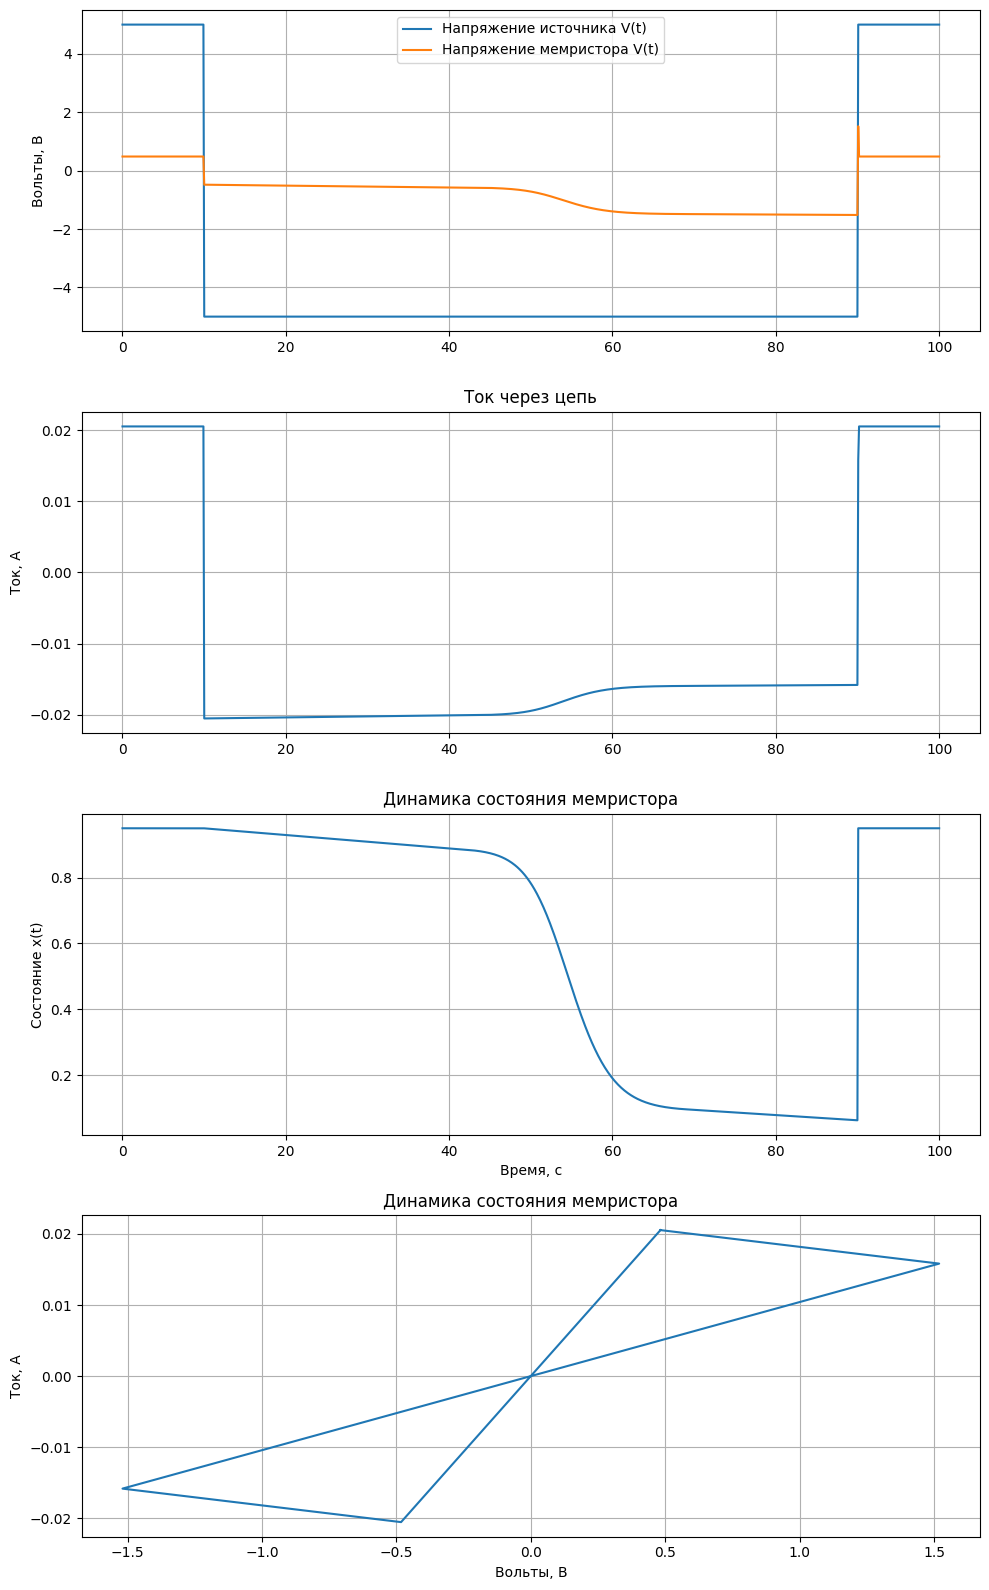

In [192]:
# ----------------------------
# Вывод графиков
# ----------------------------
plt.figure(figsize=(10, 16))

plt.subplot(4, 1, 1)
plt.plot(t, V_in, label='Напряжение источника V(t)')
plt.plot(t, V_mem, label='Напряжение мемристора V(t)')
plt.ylabel('Вольты, В')
plt.legend()
plt.grid(True)

plt.subplot(4, 1, 2)
plt.plot(t, I_mem)
plt.ylabel('Ток, А')
plt.title('Ток через цепь')
plt.grid(True)

plt.subplot(4, 1, 3)
plt.plot(t, x_mem)
plt.xlabel('Время, с')
plt.ylabel('Состояние x(t)')
plt.title('Динамика состояния мемристора')
plt.grid(True)

plt.subplot(4, 1, 4)  
plt.plot(V_mem, I_mem)
plt.xlabel('Вольты, В')
plt.ylabel('Ток, А')
plt.title('Динамика состояния мемристора')
plt.grid(True)
plt.tight_layout()
plt.show()

# Подача ЭЭГ сигнала на мемристор.

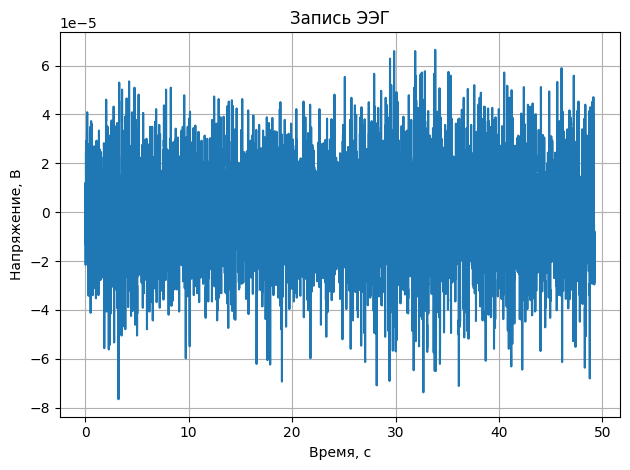

In [241]:
data_eeg = np.loadtxt("data_eeg.txt")[150:]
data_eeg[:,0] -= data_eeg[0,0]
data_eeg[:,1] -= np.mean(data_eeg[:,1])
data_eeg[:,1] /= np.std(data_eeg[:,1])
data_eeg[:,1] *= 20e-6

# data_eeg[:,1] *= 1e6

plt.plot(data_eeg[:,0], data_eeg[:,1])
plt.xlabel('Время, с')
plt.ylabel('Напряжение, В')
plt.title('Запись ЭЭГ')
plt.grid(True)
plt.tight_layout()
plt.show()

In [242]:
# ----------------------------
# Параметры схемы и моделирования
# ----------------------------
# Характеристики элементов
mem = Memristor(x_start=0.95) # мемристор

t = data_eeg[:,0]
V_in = data_eeg[:,1]
N = len(t)

# Массивы для результатов
x_mem = np.zeros(N)
I_mem = np.zeros(N)

In [243]:
for i in range(N):
    Rm = mem.get_R()
    I_mem[i] = V_in[i] / (mem.get_R())
    
    mem.upd_x(I_mem[i] * dt)
    x_mem[i] = mem.get_x()

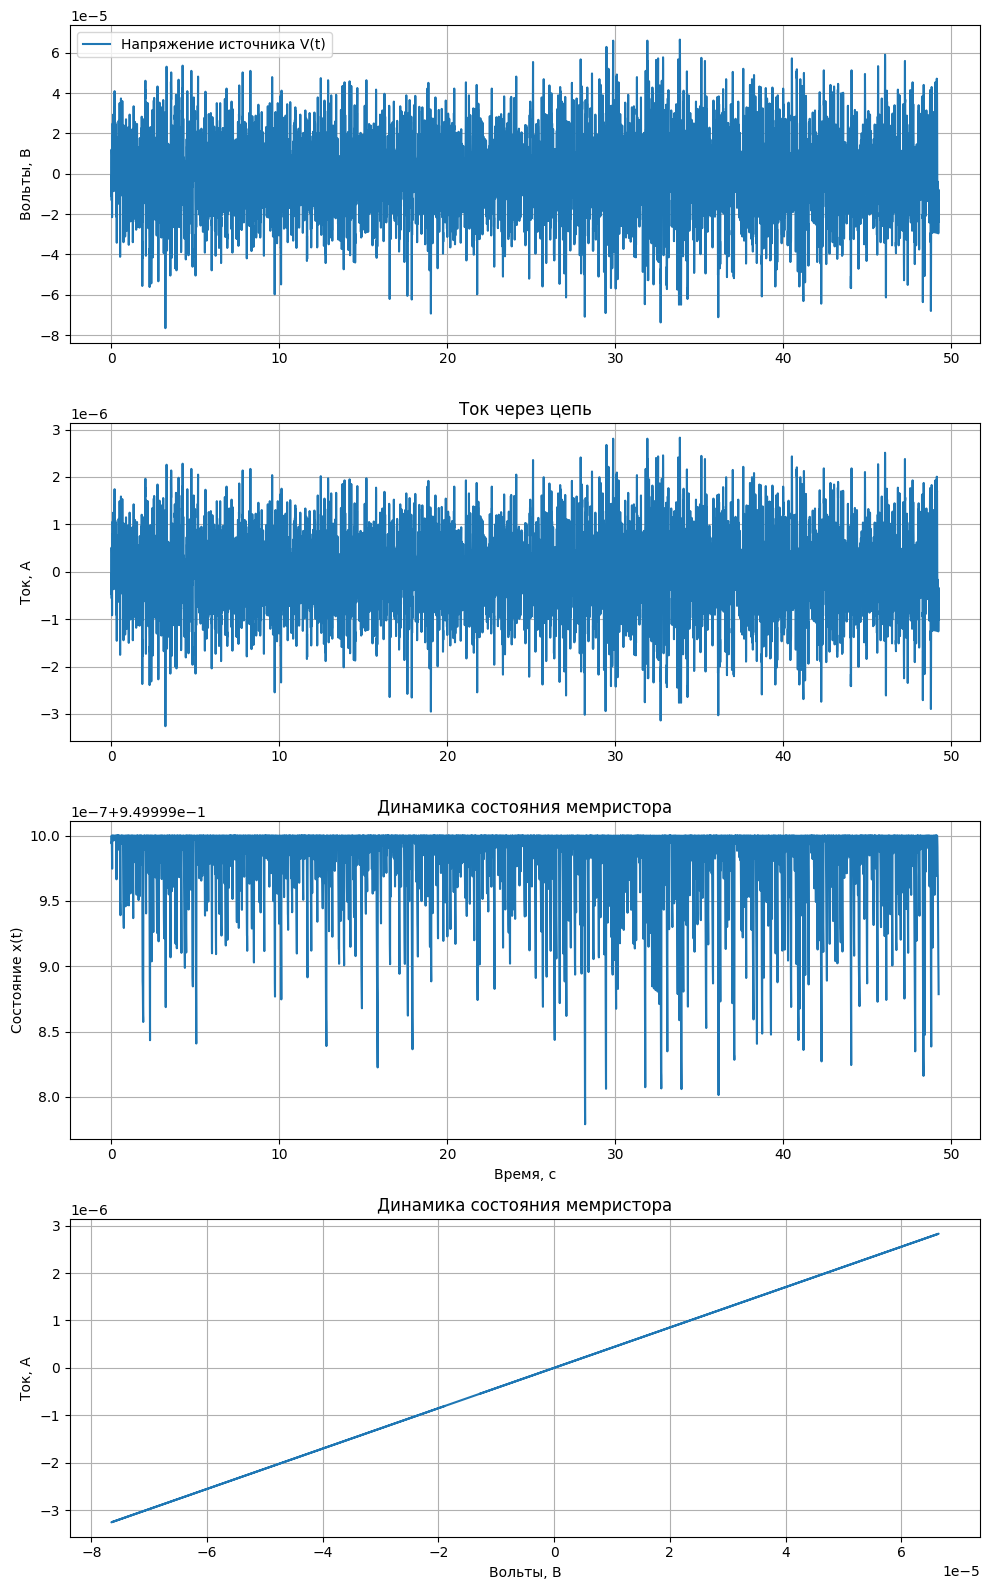

In [244]:
# ----------------------------
# Вывод графиков
# ----------------------------
plt.figure(figsize=(10, 16))

plt.subplot(4, 1, 1)
plt.plot(t, V_in, label='Напряжение источника V(t)')
plt.ylabel('Вольты, В')
plt.legend()
plt.grid(True)

plt.subplot(4, 1, 2)
plt.plot(t, I_mem)
plt.ylabel('Ток, А')
plt.title('Ток через цепь')
plt.grid(True)

plt.subplot(4, 1, 3)
plt.plot(t, x_mem)
# plt.plot(t, mem.calc_R(x_mem))
plt.xlabel('Время, с')
plt.ylabel('Состояние x(t)')
plt.title('Динамика состояния мемристора')
plt.grid(True)

plt.subplot(4, 1, 4)  
plt.plot(V_in, I_mem)
plt.xlabel('Вольты, В')
plt.ylabel('Ток, А')
plt.title('Динамика состояния мемристора')
plt.grid(True)
plt.tight_layout()
plt.show()

# Подача ПД сигнала на мемристор.

In [245]:
from scipy.integrate import odeint
import matplotlib.pyplot as plt

# Параметры модели HH
C_m = 1.0
g_Na = 120.0
g_K = 36.0
g_L = 0.3
E_Na = 50.0
E_K = -77.0
E_L = -54.4

# Функции альфа и бета (V в мВ)
def alpha_m(V): return 0.1 * (V + 40.0) / (1.0 - np.exp(-(V + 40.0) / 10.0))
def beta_m(V):  return 4.0 * np.exp(-(V + 65.0) / 18.0)
def alpha_h(V): return 0.07 * np.exp(-(V + 65.0) / 20.0)
def beta_h(V):  return 1.0 / (1.0 + np.exp(-(V + 35.0) / 10.0))
def alpha_n(V): return 0.01 * (V + 55.0) / (1.0 - np.exp(-(V + 55.0) / 10.0))
def beta_n(V):  return 0.125 * np.exp(-(V + 65.0) / 80.0)

# Система ОДУ
def hodgkin_huxley(y, t, I_ext):
    V, m, h, n = y
    I_Na = g_Na * m**3 * h * (V - E_Na)
    I_K  = g_K  * n**4 * (V - E_K)
    I_L  = g_L  * (V - E_L)
    dVdt = (I_ext - I_Na - I_K - I_L) / C_m
    dmdt = alpha_m(V) * (1 - m) - beta_m(V) * m
    dhdt = alpha_h(V) * (1 - h) - beta_h(V) * h
    dndt = alpha_n(V) * (1 - n) - beta_n(V) * n
    return [dVdt, dmdt, dhdt, dndt]

# Начальные условия
V0 = -70.0
m0 = alpha_m(V0) / (alpha_m(V0) + beta_m(V0))
h0 = alpha_h(V0) / (alpha_h(V0) + beta_h(V0))
n0 = alpha_n(V0) / (alpha_n(V0) + beta_n(V0))
y0 = [V0, m0, h0, n0]

# Временной интервал (мс)
t = np.linspace(0, 50, 1000)

# Внешний ток (можно менять!)
I_ext = 10.0  # мкА/см²

# Интегрирование
solution = odeint(hodgkin_huxley, y0, t, args=(I_ext,))
V = solution[:, 0]

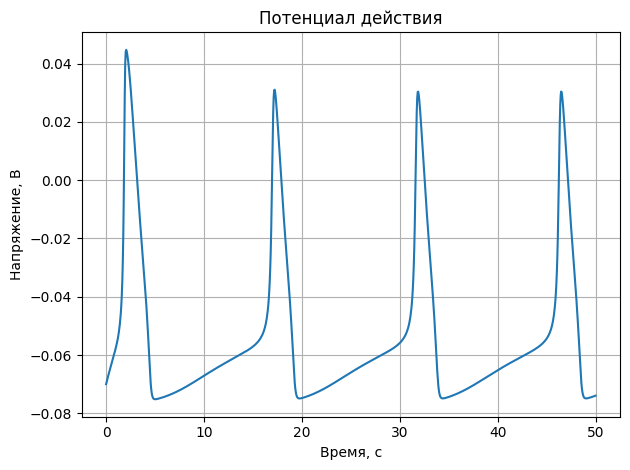

In [246]:
plt.plot(t, V/1000)
plt.xlabel('Время, с')
plt.ylabel('Напряжение, В')
plt.title('Потенциал действия')
plt.grid(True)
plt.tight_layout()
plt.show()

In [247]:
# ----------------------------
# Параметры схемы и моделирования
# ----------------------------
# Характеристики элементов
mem = Memristor(x_start=0.95) # мемристор

t = t
V_in = V/1000
N = len(t)

# Массивы для результатов
x_mem = np.zeros(N)
I_mem = np.zeros(N)

In [248]:
for i in range(N):
    Rm = mem.get_R()
    I_mem[i] = V_in[i] / (mem.get_R())
    
    mem.upd_x(I_mem[i] * dt)
    x_mem[i] = mem.get_x()

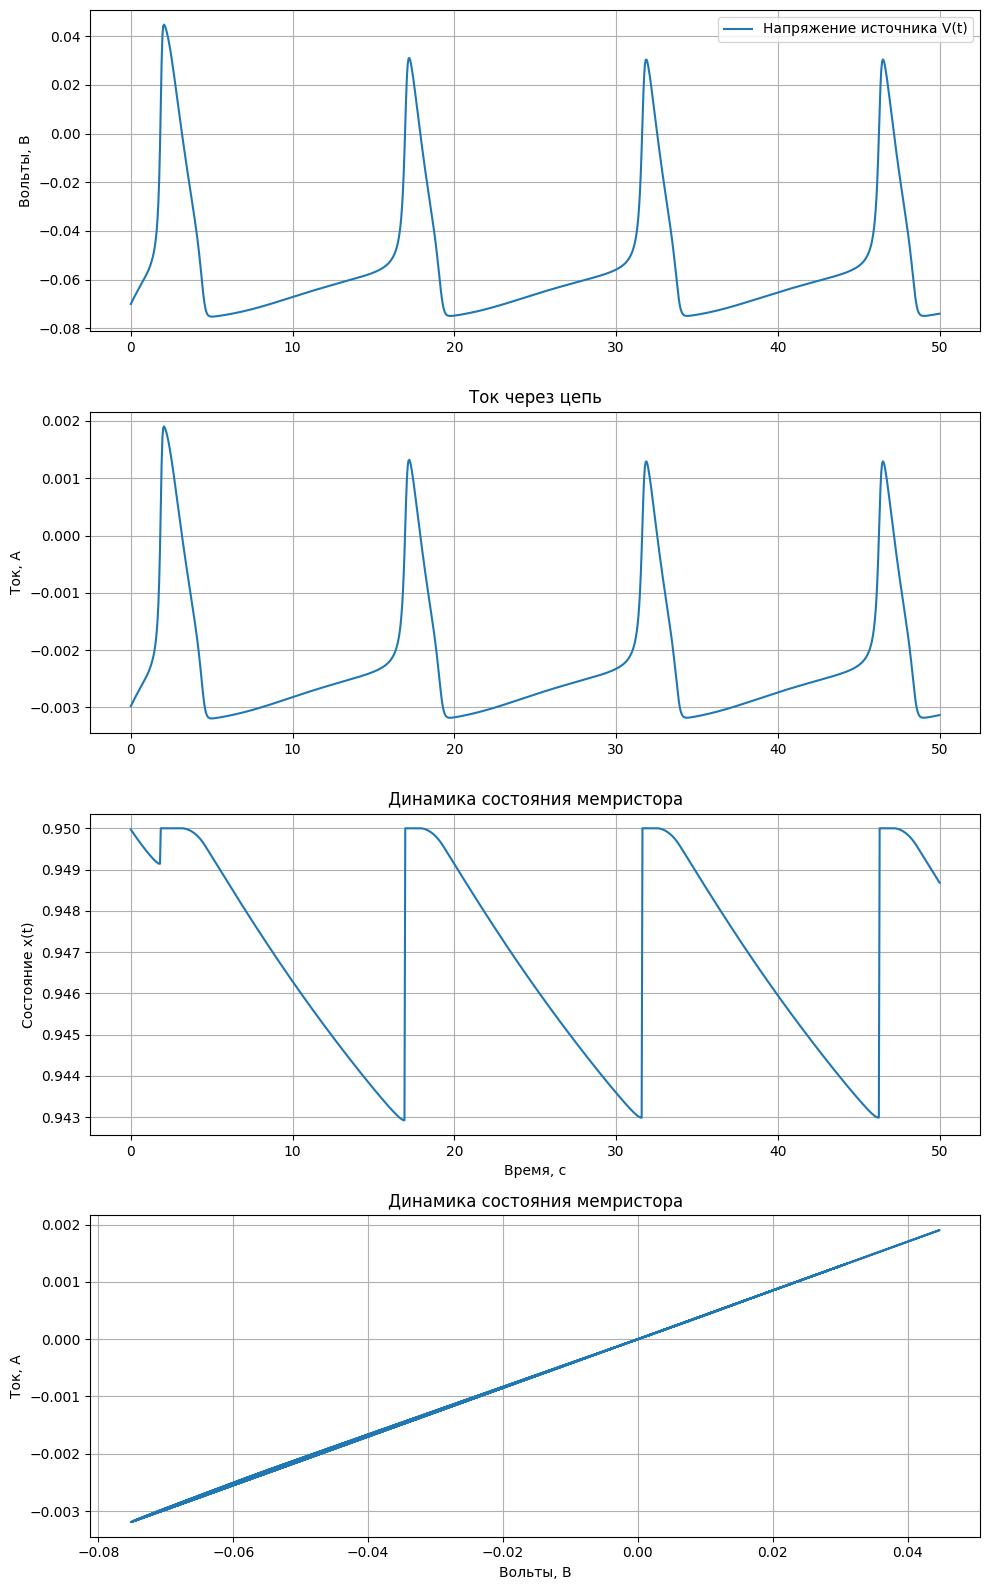

In [249]:
# ----------------------------
# Вывод графиков
# ----------------------------
plt.figure(figsize=(10, 16))

plt.subplot(4, 1, 1)
plt.plot(t, V_in, label='Напряжение источника V(t)')
plt.ylabel('Вольты, В')
plt.legend()
plt.grid(True)

plt.subplot(4, 1, 2)
plt.plot(t, I_mem)
plt.ylabel('Ток, А')
plt.title('Ток через цепь')
plt.grid(True)

plt.subplot(4, 1, 3)
plt.plot(t, x_mem)
# plt.plot(t, mem.calc_R(x_mem))
plt.xlabel('Время, с')
plt.ylabel('Состояние x(t)')
plt.title('Динамика состояния мемристора')
plt.grid(True)

plt.subplot(4, 1, 4)  
plt.plot(V_in, I_mem)
plt.xlabel('Вольты, В')
plt.ylabel('Ток, А')
plt.title('Динамика состояния мемристора')
plt.grid(True)
plt.tight_layout()
plt.show()